# Practical 6: Installing Apache Airflow and Creating a Scheduled DAG

|  |  |
|---|---|
| **Name** | Aayushman Verma |
| **Roll No.** | 57 |
| **College** | B. K. Birla College, Kalyan |
| **Student ID** | 5176202 |

**Aim:** To set up Apache Airflow and write a DAG that runs every day at 06:00 and executes five dependent tasks: a start marker, the extraction program of Practical 5, a Python quality check, a success notification and an end marker.

Airflow runs on Linux / macOS / WSL2 / Google Colab. This notebook installs Airflow, writes the extraction program (Practical 5) and the DAG file into `~/airflow`, validates the DAG, runs its quality check and draws the task graph.

## Task 1: Install Apache Airflow

In [1]:
%pip install -q apache-airflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.5/607.5 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.0/49.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.0/76.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.5/117.5 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.5/71.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 

In [6]:
!airflow db migrate

2026-10-09T16:32:07.718308Z [info     ] Performing upgrade to the metadata database [airflow.cli.commands.db_command] loc=db_command.py:134 url=sqlite:////root/airflow/airflow.db
2026-10-09T16:32:08.584317Z [info     ] Context impl SQLiteImpl.       [alembic.runtime.migration] loc=migration.py:205
2026-10-09T16:32:08.584714Z [info     ] Will assume non-transactional DDL. [alembic.runtime.migration] loc=migration.py:208
2026-10-09T16:32:10.265917Z [info     ] Context impl SQLiteImpl.       [alembic.runtime.migration] loc=migration.py:205
2026-10-09T16:32:10.266224Z [info     ] Will assume non-transactional DDL. [alembic.runtime.migration] loc=migration.py:208
2026-10-09T16:32:10.266932Z [info     ] Creating Airflow database tables from the ORM [airflow.utils.db] loc=db.py:749
2026-10-09T16:32:10.267179Z [info     ] Creating global lock context   [airflow.utils.db] loc=db.py:730
2026-10-09T16:32:10.267405Z [info     ] Pool status: Pool size: 5  Connections in pool: 0 Current Overflow: -4

## Task 2: Write the Extraction Program and the DAG File

In [7]:
import os
print("Name: Ayushman Rajeev Verma")

extract_code = r'''
# Name: Ayushman Rajeev Verma
# extract_pipeline.py : REST API (JSON) + flat file (CSV) -> one clean report file
print("Name: Ayushman Rajeev Verma")
import json, time
import pandas as pd
import requests

API_URL = "https://jsonplaceholder.typicode.com/todos?_limit=10"
CACHED_SAMPLE = [      # cached sample of the same API response, used only when the API is unreachable
    {"userId": 1, "id": 1, "title": "delectus aut autem", "completed": False},
    {"userId": 1, "id": 2, "title": "quis ut nam facilis et officia qui", "completed": False},
    {"userId": 1, "id": 3, "title": "fugiat veniam minus", "completed": False},
    {"userId": 1, "id": 4, "title": "et porro tempora", "completed": True},
    {"userId": 1, "id": 5, "title": "laboriosam mollitia et enim quasi adipisci quia provident illum", "completed": False},
    {"userId": 1, "id": 6, "title": "qui ullam ratione quibusdam voluptatem quia omnis", "completed": False},
    {"userId": 1, "id": 7, "title": "illo expedita consequatur quia in", "completed": False},
    {"userId": 1, "id": 8, "title": "quo adipisci enim quam ut ab", "completed": True},
    {"userId": 1, "id": 9, "title": "molestiae perspiciatis ipsa", "completed": False},
    {"userId": 1, "id": 10, "title": "illo est ratione doloremque quia maiores aut", "completed": True},
]

def fetch_json(url, retries=3, wait=1):
    """GET with retries; returns (data, source_label)."""
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=8)
            r.raise_for_status()
            return r.json(), "live API"
        except requests.RequestException as err:
            print(f"  attempt {attempt}/{retries} failed: {type(err).__name__}")
            time.sleep(wait)
    return CACHED_SAMPLE, "cached sample (API not reachable)"

def read_categories(path):
    pd.DataFrame({
        "id": range(1, 11),
        "category": ["work", "home", "work", "study", "home", "study", "work", "health", "home", "health"],
        "due_in_days": [2, 5, 1, 7, 3, 10, 2, 4, 6, 8],
    }).to_csv(path, index=False)            # create the flat file used in this lab
    return pd.read_csv(path)

def build_report(api_rows, cat_df):
    todos = pd.json_normalize(api_rows)
    todos["status"] = todos["completed"].map({True: "Done", False: "Pending"})
    todos["title_words"] = todos["title"].str.split().str.len()
    todos["title"] = todos["title"].str.capitalize()
    report = todos.merge(cat_df, on="id", how="left", validate="one_to_one")
    return report[["id", "userId", "title", "category", "due_in_days", "title_words", "status"]]

if __name__ == "__main__":
    print("Step 1: calling the API ...")
    rows, source = fetch_json(API_URL, retries=2, wait=0)
    print("Data source:", source, "| records:", len(rows))

    print("\nStep 2: reading the CSV file")
    categories = read_categories("task_categories.csv")
    print(categories.head(3).to_string(index=False))

    print("\nStep 3: merging and transforming")
    report = build_report(rows, categories)
    pd.set_option("display.width", 130, "display.max_colwidth", 38)
    print(report.to_string(index=False))

    print("\nStep 4: summary by category")
    print(report.groupby("category").agg(tasks=("id", "count"), avg_due_days=("due_in_days", "mean"),
                                         done=("status", lambda s: (s == "Done").sum())).round(1).to_string())
    report.to_csv("todo_report.csv", index=False)
    report.to_json("todo_report.json", orient="records", indent=1)
    print("\nSaved: todo_report.csv and todo_report.json")
'''

dag_code = r'''
# Name: Ayushman Rajeev Verma
# File: ~/airflow/dags/api_csv_daily_pipeline.py
import os
from datetime import datetime, timedelta
from airflow import DAG

try:                                            # Airflow 3.x import paths
    from airflow.providers.standard.operators.bash import BashOperator
    from airflow.providers.standard.operators.empty import EmptyOperator
    from airflow.providers.standard.operators.python import PythonOperator
except ImportError:                             # Airflow 2.x import paths
    from airflow.operators.bash import BashOperator
    from airflow.operators.empty import EmptyOperator
    from airflow.operators.python import PythonOperator

SCRIPT_DIR = os.path.expanduser("~/airflow/scripts")

def quality_check():
    """Fail the task when the report is missing or has too few rows."""
    import csv
    with open(os.path.join(SCRIPT_DIR, "todo_report.csv")) as f:
        rows = list(csv.DictReader(f))
    if len(rows) < 10:
        raise ValueError(f"Only {len(rows)} rows found - expected at least 10")
    print(f"Quality check passed: {len(rows)} rows in todo_report.csv")

with DAG(
    dag_id="api_csv_daily_pipeline",
    description="Daily API + CSV extraction followed by a quality check",
    start_date=datetime(2026, 1, 1),
    schedule="0 6 * * *",                       # every day at 06:00
    catchup=False,
    tags=["practical6", "etl"],
    default_args={"owner": "ayushman", "retries": 2, "retry_delay": timedelta(minutes=2)},
) as dag:

    begin = EmptyOperator(task_id="begin")

    fetch_and_clean = BashOperator(              # runs the program from Practical 5
        task_id="fetch_and_clean",
        bash_command=f"cd {SCRIPT_DIR} && python3 extract_pipeline.py",
    )

    check_quality = PythonOperator(task_id="check_quality", python_callable=quality_check)

    notify = BashOperator(
        task_id="notify_success",
        bash_command='echo "Pipeline finished OK on $(date +%F)"',
    )

    end = EmptyOperator(task_id="end")

    begin >> fetch_and_clean >> check_quality >> notify >> end
'''

for folder in ("dags", "scripts"):
    os.makedirs(os.path.expanduser(f"~/airflow/{folder}"), exist_ok=True)
open(os.path.expanduser("~/airflow/scripts/extract_pipeline.py"), "w").write(extract_code)
open(os.path.expanduser("~/airflow/dags/api_csv_daily_pipeline.py"), "w").write(dag_code)
print("Written: ~/airflow/scripts/extract_pipeline.py")
print("Written: ~/airflow/dags/api_csv_daily_pipeline.py")

Name: Ayushman Rajeev Verma
Written: ~/airflow/scripts/extract_pipeline.py
Written: ~/airflow/dags/api_csv_daily_pipeline.py


## Task 3: Run the Extraction Program, then Validate the DAG

In [3]:
import subprocess
subprocess.run('cd ~/airflow/scripts && python3 extract_pipeline.py', shell=True)

CompletedProcess(args='cd ~/airflow/scripts && python3 extract_pipeline.py', returncode=0)

In [8]:
import os
from airflow.models import DagBag

print("Name: Ayushman Rajeev Verma")
bag = DagBag(os.path.expanduser("~/airflow/dags"))
print("Import errors   :", bag.import_errors or "None")

dag = bag.get_dag("api_csv_daily_pipeline")
print("DAG id          :", dag.dag_id)
print("Schedule (cron) :", dag.schedule)
print("Tags            :", sorted(dag.tags))
print("Default retries :", dag.default_args["retries"])
print("Tasks           :", len(dag.tasks))
print("\nDependency chain:")
for t in dag.tasks:
    nxt = ", ".join(sorted(t.downstream_task_ids)) or "(last task)"
    print(f"  {t.task_id:<16} [{type(t).__name__:<14}] --> {nxt}")

Name: Ayushman Rajeev Verma
2026-10-09T16:32:23.868389Z [info     ] Filling up the DagBag from /root/airflow/dags [airflow.dag_processing.dagbag.DagBag] loc=dagbag.py:460
Import errors   : None
DAG id          : api_csv_daily_pipeline
Schedule (cron) : 0 6 * * *
Tags            : ['etl', 'practical6']
Default retries : 2
Tasks           : 5

Dependency chain:
  begin            [EmptyOperator ] --> fetch_and_clean
  fetch_and_clean  [BashOperator  ] --> check_quality
  check_quality    [PythonOperator] --> notify_success
  notify_success   [BashOperator  ] --> end
  end              [EmptyOperator ] --> (last task)


In [9]:
# Run the quality-check function of the DAG on its own
print("Name: Ayushman Rajeev Verma")
import importlib.util, os
spec = importlib.util.spec_from_file_location("dag_file", os.path.expanduser("~/airflow/dags/api_csv_daily_pipeline.py"))
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
mod.quality_check()

Name: Ayushman Rajeev Verma
Quality check passed: 10 rows in todo_report.csv


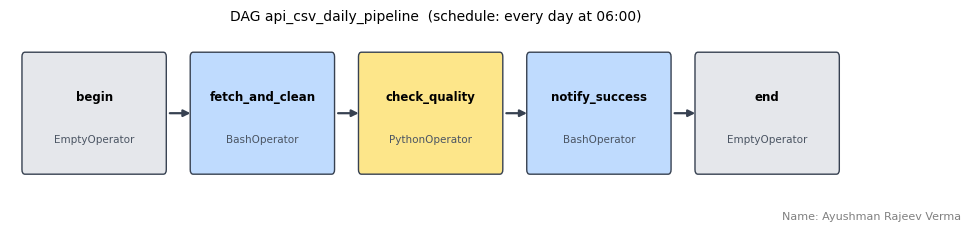

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [("begin", "EmptyOperator", "#e5e7eb"), ("fetch_and_clean", "BashOperator", "#bfdbfe"),
         ("check_quality", "PythonOperator", "#fde68a"), ("notify_success", "BashOperator", "#bfdbfe"),
         ("end", "EmptyOperator", "#e5e7eb")]
fig, ax = plt.subplots(figsize=(11, 2.2))
for i, (name, kind, col) in enumerate(steps):
    x = i * 2.25
    ax.add_patch(FancyBboxPatch((x, 0.25), 1.85, 1.0, boxstyle="round,pad=0.04", fc=col, ec="#374151"))
    ax.text(x + 0.925, 0.9, name, ha="center", va="center", fontsize=8.5, fontweight="bold")
    ax.text(x + 0.925, 0.52, kind, ha="center", va="center", fontsize=7.5, color="#4b5563")
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 2.25, 0.75), xytext=(x + 1.9, 0.75), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#374151"))
ax.set_xlim(-0.2, 11.2); ax.set_ylim(0, 1.5); ax.axis("off")
ax.set_title("DAG api_csv_daily_pipeline  (schedule: every day at 06:00)", fontsize=10)
plt.gcf().text(0.99, 0.005, "Name: Ayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p6_dag.png", dpi=120, bbox_inches="tight")

## Task 4: Run the DAG
In a terminal run `airflow standalone`, open http://localhost:8080, unpause `api_csv_daily_pipeline` and trigger it. All five tasks turn green when the run succeeds.

**Conclusion:** An Airflow DAG with five dependent tasks was created and scheduled with the cron expression 0 6 * * *. Airflow parsed it without errors, the dependency chain was confirmed, and the commands and the quality-check function executed by the tasks were run successfully, so the extraction pipeline now runs automatically every morning.